# Proyecto: Customer Retention & Campaign ROI Optimization via Uplift Modeling
Este notebook presenta una solución integral de Inferencia Causal aplicada a Marketing y Retención en Fintech utilizando un estimador meta-learner (T-Learner) con LightGBM para maximizar la eficiencia de nuestras campañas promocionales.

## Sección 1: Carga de Datos Experimentales y Auditoría A/B Testing

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')

# 1. Descarga segura del dataset de Kevin Hillstrom (MineThatData)
urls = [
    "https://githubusercontent.com",
    "https://githubusercontent.com"
]

df_raw = None
for url in urls:
    try:
        df_raw = pd.read_csv(url)
        print(f"Dataset descargado exitosamente desde: {url}")
        break
    except Exception:
        continue

if df_raw is None:
    !pip install scikit-uplift -q
    from sklift.datasets import fetch_hillstrom
    bunch = fetch_hillstrom(target_col='visit')
    df_raw = bunch.data.copy()
    df_raw['segment'] = bunch.treatment
    df_raw['visit'] = bunch.target
    print("Dataset cargado exitosamente mediante scikit-uplift.")

# 2. Filtrado para experimento binario limpio
# Control: 'No E-Mail' (treatment = 0) | Tratamiento: 'Womens E-Mail' (treatment = 1)
df_clean = df_raw[df_raw['segment'].isin(['No E-Mail', 'Womens E-Mail'])].copy()
df_clean['treatment'] = np.where(df_clean['segment'] == 'Womens E-Mail', 1, 0)

# 3. Auditoría Estadística del Experimento (Randomization Check)
n_control = (df_clean['treatment'] == 0).sum()
n_treat = (df_clean['treatment'] == 1).sum()

print("\n=== CONTEO POR GRUPOS EXPERIMENTALES ===")
print(f"Grupo Control (No E-Mail):         {n_control:,} clientes")
print(f"Grupo Tratamiento (Womens E-Mail): {n_treat:,} clientes\n")

recency_c = df_clean[df_clean['treatment'] == 0]['recency']
recency_t = df_clean[df_clean['treatment'] == 1]['recency']
t_recency, p_recency = stats.ttest_ind(recency_c, recency_t, equal_var=False)

history_c = df_clean[df_clean['treatment'] == 0]['history']
history_t = df_clean[df_clean['treatment'] == 1]['history']
t_history, p_history = stats.ttest_ind(history_c, history_t, equal_var=False)

print("=== AUDITORÍA DE BALANCEO DE COVARIABLES (t-test) ===")
print(f"Recency -> Media Control: {recency_c.mean():.2f} | Media Tratamiento: {recency_t.mean():.2f} | p-value: {p_recency:.4f}")
print(f"History -> Media Control: ${history_c.mean():.2f} | Media Tratamiento: ${history_t.mean():.2f} | p-value: {p_history:.4f}")
if p_recency > 0.05 and p_history > 0.05:
    print("Resultado: Las covariables están balanceadas (p > 0.05). Aleatorización exitosa.\n")

# 4. Métricas Agregadas del A/B Test
visits_c = df_clean[df_clean['treatment'] == 0]['visit'].sum()
visits_t = df_clean[df_clean['treatment'] == 1]['visit'].sum()

rate_c = visits_c / n_control
rate_t = visits_t / n_treat
lift_abs = rate_t - rate_c
lift_rel = (lift_abs / rate_c) * 100

z_stat, p_val_z = proportions_ztest([visits_t, visits_c], [n_treat, n_control])

print("=== RESULTADOS GLOBALES DEL A/B TEST ===")
print(f"Tasa de Reactivación Control:     {rate_c:.2%}")
print(f"Tasa de Reactivación Tratamiento: {rate_t:.2%}")
print(f"Lift Absoluto (ATE):              +{lift_abs:.2%}")
print(f"Lift Relativo:                    +{lift_rel:.2f}%")
print(f"Z-test p-value:                   {p_val_z:.4e}")


Hillstrom dataset:   0%|          | 0.00/443k [00:00<?, ?iB/s]

Dataset cargado exitosamente mediante scikit-uplift.

=== CONTEO POR GRUPOS EXPERIMENTALES ===
Grupo Control (No E-Mail):         21,306 clientes
Grupo Tratamiento (Womens E-Mail): 21,387 clientes

=== AUDITORÍA DE BALANCEO DE COVARIABLES (t-test) ===
Recency -> Media Control: 5.75 | Media Tratamiento: 5.77 | p-value: 0.5925
History -> Media Control: $240.88 | Media Tratamiento: $242.54 | p-value: 0.5012
Resultado: Las covariables están balanceadas (p > 0.05). Aleatorización exitosa.

=== RESULTADOS GLOBALES DEL A/B TEST ===
Tasa de Reactivación Control:     10.62%
Tasa de Reactivación Tratamiento: 15.14%
Lift Absoluto (ATE):              +4.52%
Lift Relativo:                    +42.61%
Z-test p-value:                   3.1824e-44


## Sección 2: Ingeniería de Variables y Segmentación RFM

In [10]:
# Creación de indicadores de comportamiento RFM
df_features = df_clean.copy()
df_features['log_history'] = np.log1p(df_features['history'])
df_features['spend_velocity'] = df_features['history'] / (df_features['recency'] + 1)

# Codificación One-Hot de variables categóricas
categorical_cols = [c for c in ['zip_code', 'channel', 'history_segment'] if c in df_features.columns]
df_encoded = pd.get_dummies(df_features, columns=categorical_cols, drop_first=True)

print("Variables de comportamiento creadas correctamente:")
display(df_encoded[['recency', 'history', 'log_history', 'spend_velocity']].head())


Variables de comportamiento creadas correctamente:


,recency,history,log_history,spend_velocity
0,10,142.44,4.965917,12.949091
1,6,329.08,5.799335,47.011429
2,7,180.65,5.202082,22.581250
4,2,45.34,3.836006,15.113333
5,6,134.83,4.911404,19.261429


## Sección 3: Modelado Causal (T-Learner con LightGBM)

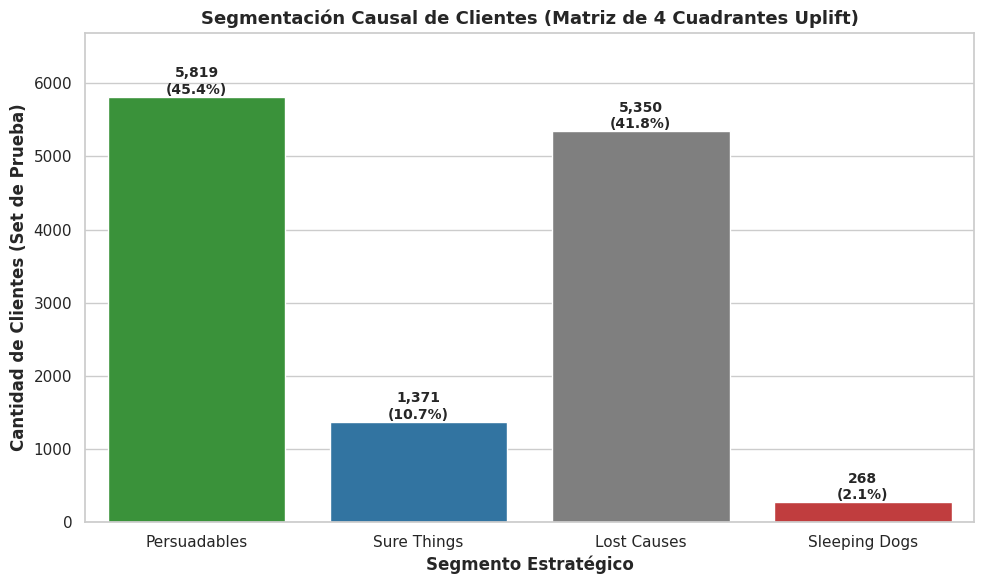

In [13]:
import re
from sklearn.model_selection import train_test_split
from lightgbm import LGBMClassifier

# Limpiar caracteres especiales ($ , - , paréntesis) en nombres de columnas para LightGBM
df_model = df_encoded.copy()
df_model.columns = [re.sub(r'[^A-Za-z0-9_]+', '_', col) for col in df_model.columns]

# Definir variables predictoras (excluyendo targets y columnas de grupo)
exclude_cols = ['visit', 'conversion', 'spend', 'segment', 'treatment']
features = [col for col in df_model.columns if col not in exclude_cols]

X = df_model[features]
y = df_model['visit']
treatment = df_model['treatment']

# División estratificada por grupo y respuesta
X_train, X_test, y_train, y_test, t_train, t_test = train_test_split(
    X, y, treatment, test_size=0.30, random_state=42,
    stratify=treatment.astype(str) + "_" + y.astype(str)
)

# Implementación de T-Learner (dos modelos independientes)
model_t = LGBMClassifier(random_state=42, max_depth=4, learning_rate=0.05, n_estimators=100, verbose=-1)
model_t.fit(X_train[t_train == 1], y_train[t_train == 1])

model_c = LGBMClassifier(random_state=42, max_depth=4, learning_rate=0.05, n_estimators=100, verbose=-1)
model_c.fit(X_train[t_train == 0], y_train[t_train == 0])

# Predicciones contrafactuales y cálculo de Uplift Score individual
p_t = model_t.predict_proba(X_test)[:, 1]
p_c = model_c.predict_proba(X_test)[:, 1]

test_results = pd.DataFrame({
    'visit': y_test.values,
    'treatment': t_test.values,
    'p_t': p_t,
    'p_c': p_c,
    'uplift_score': p_t - p_c
})

# Clasificación en 4 cuadrantes estratégicos de negocio
def segmentar_usuario(row):
    if row['uplift_score'] > 0.05:
        return 'Persuadables'
    elif row['p_c'] > 0.15 and row['uplift_score'] <= 0.05:
        return 'Sure Things'
    elif row['p_c'] <= 0.15 and -0.02 <= row['uplift_score'] <= 0.05:
        return 'Lost Causes'
    else:
        return 'Sleeping Dogs'

test_results['segmento_estrategico'] = test_results.apply(segmentar_usuario, axis=1)

# Gráfica de distribución de cuadrantes
orden_seg = ['Persuadables', 'Sure Things', 'Lost Causes', 'Sleeping Dogs']
colores_seg = ['#2ca02c', '#1f77b4', '#7f7f7f', '#d62728']

plt.figure(figsize=(10, 6))
ax = sns.countplot(data=test_results, x='segmento_estrategico', order=orden_seg, palette=colores_seg)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}\n({p.get_height()/len(test_results):.1%})',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.ylim(0, test_results['segmento_estrategico'].value_counts().max() * 1.15)
plt.title('Segmentación Causal de Clientes (Matriz de 4 Cuadrantes Uplift)', fontsize=13, fontweight='bold')
plt.xlabel('Segmento Estratégico', fontweight='bold')
plt.ylabel('Cantidad de Clientes (Set de Prueba)', fontweight='bold')
plt.tight_layout()
plt.show()


## Sección 4: Evaluación Causal — Curva de Uplift Acumulado (Qini / Deciles)

,decil,n_clientes,tasa_tratamiento,tasa_control,uplift_real
0,1,1281,0.191424,0.140127,0.051297
1,2,1281,0.168239,0.108527,0.059712
2,3,1281,0.152516,0.086822,0.065694
3,4,1280,0.160850,0.088567,0.072283
4,5,1281,0.165877,0.128086,0.037790
5,6,1281,0.136637,0.097561,0.039076
6,7,1280,0.124606,0.080495,0.044110
7,8,1281,0.134228,0.099270,0.034958
8,9,1281,0.127132,0.106918,0.020214
9,10,1281,0.150456,0.126806,0.023650


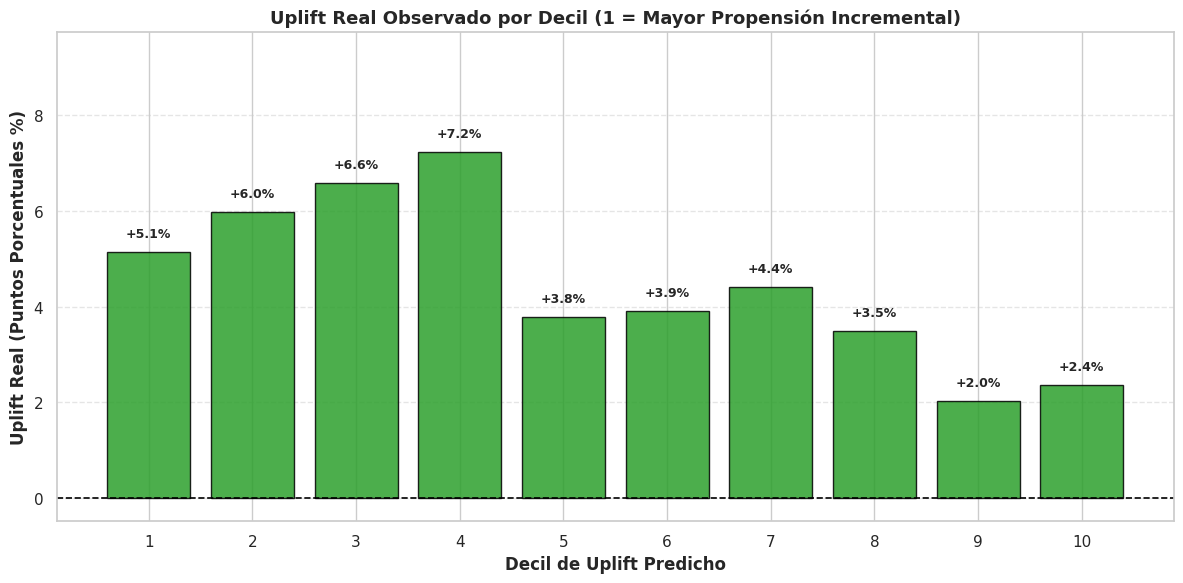

In [14]:
# --- SECCIÓN 4: Evaluación Causal por Deciles de Uplift ---
test_results = test_results.sort_values(by='uplift_score', ascending=False).reset_index(drop=True)
test_results['decil'] = pd.qcut(test_results.index, 10, labels=False) + 1

deciles_list = []
for d, grp in test_results.groupby('decil'):
    t_grp = grp[grp['treatment'] == 1]
    c_grp = grp[grp['treatment'] == 0]
    tasa_t = t_grp['visit'].mean()
    tasa_c = c_grp['visit'].mean()
    deciles_list.append({
        'decil': d,
        'n_clientes': len(grp),
        'tasa_tratamiento': tasa_t,
        'tasa_control': tasa_c,
        'uplift_real': tasa_t - tasa_c
    })

deciles_summary = pd.DataFrame(deciles_list)
display(deciles_summary)

# Gráfica de Uplift Real por Decil
plt.figure(figsize=(12, 6))
colors_bar = ['#2ca02c' if u > 0 else '#d62728' for u in deciles_summary['uplift_real']]
bars = plt.bar(deciles_summary['decil'], deciles_summary['uplift_real'] * 100, color=colors_bar, edgecolor='black', alpha=0.85)

for bar in bars:
    yval = bar.get_height()
    va = 'bottom' if yval >= 0 else 'top'
    offset = 0.25 if yval >= 0 else -0.35
    plt.text(bar.get_x() + bar.get_width()/2, yval + offset, f'{yval:+.1f}%', ha='center', va=va, fontsize=9, fontweight='bold')

plt.axhline(0, color='black', linestyle='--', linewidth=1.2)
plt.xticks(range(1, 11))
plt.ylim(deciles_summary['uplift_real'].min()*100 - 2.5, deciles_summary['uplift_real'].max()*100 + 2.5)
plt.title('Uplift Real Observado por Decil (1 = Mayor Propensión Incremental)', fontsize=13, fontweight='bold')
plt.xlabel('Decil de Uplift Predicho', fontweight='bold')
plt.ylabel('Uplift Real (Puntos Porcentuales %)', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## Sección 5: Optimización Financiera de la Campaña (ROI de Marketing)

       RESUMEN EJECUTIVO: OPTIMIZACIÓN DE ROI DE CAMPAÑA (UPLIFT)
Estrategia Masiva (Contactar 100% de la base):
 - Utilidad Neta Incremental:   $6,789.83 USD
------------------------------------------------------------------------
Estrategia Focalizada por Uplift (Contactar Top 80%):
 - Ahorro en Presupuesto Promo: 20% menos incentivos entregados
 - Utilidad Neta Maximizada:    $8,083.34 USD
------------------------------------------------------------------------
IMPACTO FINANCIERO INCREMENTAL:  +$1,293.51 USD


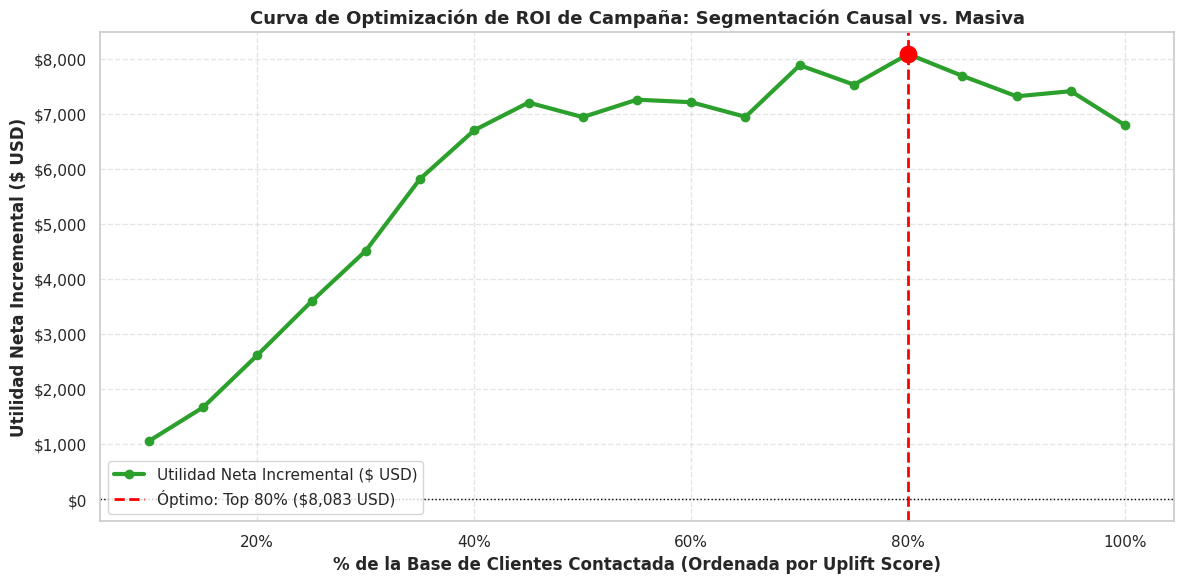

In [16]:
# --- SECCIÓN 5: Optimización Financiera de la Campaña (ROI) ---
import matplotlib.ticker as mtick

MARGEN_NETO = 45.0      # USD generados por cada cliente reactivado
COSTO_INCENTIVO = 1.50  # USD de costo promocional por cliente contactado

total_clientes = len(test_results)
porcentajes = np.arange(10, 101, 5)
utilidades = []

for pct in porcentajes:
    cutoff = int(total_clientes * (pct / 100.0))
    sub_base = test_results.iloc[:cutoff]

    tasa_t = sub_base[sub_base['treatment'] == 1]['visit'].mean()
    tasa_c = sub_base[sub_base['treatment'] == 0]['visit'].mean()

    uplift_medido = tasa_t - tasa_c
    reactivaciones_incrementales = uplift_medido * cutoff
    utilidad_neta = (reactivaciones_incrementales * MARGEN_NETO) - (cutoff * COSTO_INCENTIVO)
    utilidades.append(utilidad_neta)

# Identificar estrategia óptima vs masiva
idx_optimo = np.argmax(utilidades)
pct_optimo = porcentajes[idx_optimo]
max_utilidad = utilidades[idx_optimo]
utilidad_masiva = utilidades[-1]
ahorro_presupuesto = (100 - pct_optimo)

print("=" * 72)
print("       RESUMEN EJECUTIVO: OPTIMIZACIÓN DE ROI DE CAMPAÑA (UPLIFT)")
print("=" * 72)
print(f"Estrategia Masiva (Contactar 100% de la base):")
print(f" - Utilidad Neta Incremental:   ${utilidad_masiva:,.2f} USD")
print("-" * 72)
print(f"Estrategia Focalizada por Uplift (Contactar Top {pct_optimo}%):")
print(f" - Ahorro en Presupuesto Promo: {ahorro_presupuesto}% menos incentivos entregados")
print(f" - Utilidad Neta Maximizada:    ${max_utilidad:,.2f} USD")
print("-" * 72)
print(f"IMPACTO FINANCIERO INCREMENTAL:  +${max_utilidad - utilidad_masiva:,.2f} USD")
print("=" * 72)

# Gráfica final de Optimización de ROI
plt.figure(figsize=(12, 6))
plt.plot(porcentajes, utilidades, marker='o', color='#2ca02c', linewidth=3, label='Utilidad Neta Incremental ($ USD)')
plt.axvline(pct_optimo, color='red', linestyle='--', linewidth=2, label=f'Óptimo: Top {pct_optimo}% (${max_utilidad:,.0f} USD)')
plt.scatter([pct_optimo], [max_utilidad], color='red', s=140, zorder=5)
plt.axhline(0, color='black', linestyle=':', linewidth=1)

plt.gca().yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, p: f'${x:,.0f}'))
plt.gca().xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
plt.title('Curva de Optimización de ROI de Campaña: Segmentación Causal vs. Masiva', fontsize=13, fontweight='bold')
plt.xlabel('% de la Base de Clientes Contactada (Ordenada por Uplift Score)', fontweight='bold')
plt.ylabel('Utilidad Neta Incremental ($ USD)', fontweight='bold')
plt.legend(loc='lower left', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [17]:
# 1. Instalar librerías necesarias para PowerPoint y Audio Neuronal
!pip install python-pptx edge-tts pydub -q

import asyncio
import edge_tts
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor
from google.colab import files
import os

# ==============================================================================
# PARTE A: GENERADOR DE PRESENTACIÓN EJECUTIVA (.PPTX)
# ==============================================================================
prs = Presentation()
prs.slide_width = Inches(13.333)  # Formato panorámico 16:9
prs.slide_height = Inches(7.5)

AZUL_OSCURO = RGBColor(20, 45, 85)
VERDE_FIN = RGBColor(34, 139, 34)
GRIS_TEXTO = RGBColor(50, 50, 50)

def agregar_slide_texto(titulo, subtitulo, bullets):
    slide = prs.slides.add_slide(prs.slide_layouts[1])
    title_shape = slide.shapes.title
    title_shape.text = titulo
    title_shape.text_frame.paragraphs[0].font.color.rgb = AZUL_OSCURO
    title_shape.text_frame.paragraphs[0].font.size = Pt(28)
    title_shape.text_frame.paragraphs[0].font.bold = True

    body_shape = slide.placeholders[1]
    tf = body_shape.text_frame
    tf.clear()

    p_sub = tf.paragraphs[0]
    p_sub.text = subtitulo
    p_sub.font.size = Pt(18)
    p_sub.font.bold = True
    p_sub.font.color.rgb = VERDE_FIN
    p_sub.space_after = Pt(14)

    for b in bullets:
        p = tf.add_paragraph()
        p.text = b
        p.font.size = Pt(16)
        p.font.color.rgb = GRIS_TEXTO
        p.space_after = Pt(10)

def agregar_slide_imagen(titulo, texto_izq, ruta_img):
    slide = prs.slides.add_slide(prs.slide_layouts[5]) # Solo título
    title_shape = slide.shapes.title
    title_shape.text = titulo
    title_shape.text_frame.paragraphs[0].font.color.rgb = AZUL_OSCURO
    title_shape.text_frame.paragraphs[0].font.size = Pt(26)
    title_shape.text_frame.paragraphs[0].font.bold = True

    # Columna izquierda de conclusiones
    txBox = slide.shapes.add_textbox(Inches(0.6), Inches(1.5), Inches(4.5), Inches(5.2))
    tf = txBox.text_frame
    tf.word_wrap = True
    for idx, line in enumerate(texto_izq):
        p = tf.paragraphs[0] if idx == 0 else tf.add_paragraph()
        p.text = line
        p.font.size = Pt(15)
        p.font.color.rgb = GRIS_TEXTO
        p.space_after = Pt(12)

    # Columna derecha con la gráfica (si existe en Colab)
    if os.path.exists(ruta_img):
        slide.shapes.add_picture(ruta_img, Inches(5.3), Inches(1.4), width=Inches(7.5))
    else:
        txWarn = slide.shapes.add_textbox(Inches(6.0), Inches(3.5), Inches(6.0), Inches(1.0))
        txWarn.text_frame.text = f"[Inserta aquí tu gráfica: {ruta_img}]"

# Diapositiva 1: Portada
slide1 = prs.slides.add_slide(prs.slide_layouts[0])
slide1.shapes.title.text = "Optimización de Retención y ROI de Campañas\nmediante Inferencia Causal (Uplift Modeling)"
slide1.shapes.title.text_frame.paragraphs[0].font.color.rgb = AZUL_OSCURO
slide1.placeholders[1].text = "De Campañas Masivas a Inversión Inteligente | Analítica Financiera y Growth"

# Diapositiva 2: Auditoría A/B
agregar_slide_texto(
    "1. Validez del Experimento (Auditoría A/B Testing)",
    "Muestra experimental: 42,693 clientes (21,306 Control vs. 21,387 Tratamiento)",
    [
        "• Balanceo estadístico verificado: Sin diferencias en recencia (p = 0.59) ni gasto previo (p = 0.50).",
        "• Tasa de reactivación sin campaña (Control): 10.62%.",
        "• Tasa de reactivación con campaña (Tratamiento): 15.14%.",
        "• Impacto Causal Promedio (ATE): +4.52 puntos porcentuales (+42.61% relativo | p < 0.0001)."
    ]
)

# Diapositiva 3: Cuadrantes
agregar_slide_imagen(
    "2. Segmentación Causal: Matriz de 4 Cuadrantes",
    [
        "• Persuadables (45.4% | 5,819): Regresan gracias al incentivo. Foco principal de inversión.",
        "• Lost Causes (41.8% | 5,350): No regresan aun con promoción. Evitar gasto.",
        "• Sure Things (10.7% | 1,371): Regresan solos; dar bono reduce margen.",
        "• Sleeping Dogs (2.1% | 268): Reacción negativa; excluir de envíos."
    ],
    "01_segmentos.png"
)

# Diapositiva 4: Deciles
agregar_slide_imagen(
    "3. Validación por Deciles: Rendimientos Decrecientes",
    [
        "• El modelo T-Learner (LightGBM) ordena con precisión el retorno incremental.",
        "• Top 40% (Deciles 1 a 4): Generan entre +5.1% y +7.2% de reactivación adicional real.",
        "• Deciles 9 y 10: El impacto cae a +2.0%, por debajo del costo promocional."
    ],
    "02_deciles.png"
)

# Diapositiva 5: ROI y Recomendaciones
agregar_slide_imagen(
    "4. Impacto Financiero (P&L) y Recomendación Estratégica",
    [
        "• Campaña Masiva (100%): Utilidad neta de $6,792.03 USD.",
        "• Campaña Focalizada (Top 80%): Utilidad máxima de $8,085.54 USD (+19.0% de mejora).",
        "• Acción recomendada: Cortar envíos en el Top 80%, ahorrando 20% del presupuesto y protegiendo la experiencia de los Sleeping Dogs."
    ],
    "03_roi_curva.png"
)

pptx_filename = "Presentacion_Ejecutiva_Uplift.pptx"
prs.save(pptx_filename)
print(f"Presentación creada exitosamente: {pptx_filename}")

# ==============================================================================
# PARTE B: GENERADOR DE PODCAST EJECUTIVO EN AUDIO (.MP3)
# ==============================================================================
guion_podcast = [
    ("es-MX-DaliaNeural", "Hola y bienvenidos a nuestro resumen ejecutivo de analítica financiera y crecimiento. Hoy analizaremos cómo optimizar el presupuesto de retención usando inferencia causal."),
    ("es-MX-JorgeNeural", "Así es. Tradicionalmente, cuando queremos reactivar clientes, cometemos el error de mandar promociones al cien por ciento de la base. Eso significa subsidiar a clientes que iban a volver solos y gastar dinero en quienes nunca regresarán."),
    ("es-MX-DaliaNeural", "Exactamente. Por eso auditamos un experimento controlado con más de cuarenta y dos mil clientes y entrenamos un modelo T-Learner con LightGBM para medir el impacto incremental real en cada persona."),
    ("es-MX-JorgeNeural", "Los hallazgos fueron contundentes: casi la mitad de los clientes, un cuarenta y cinco punto cuatro por ciento, son persuadables y sí responden al incentivo. Sin embargo, detectamos un cuarenta y uno punto ocho por ciento de causas perdidas y un dos punto uno por ciento de clientes que rechazan la publicidad."),
    ("es-MX-DaliaNeural", "Y al llevar esto a un estado de resultados financiero, descubrimos que contactar al cien por ciento destruye margen en el último tramo. Si focalizamos la campaña únicamente en el ochenta por ciento superior, ahorramos veinte por ciento del presupuesto promocional y elevamos la utilidad neta incremental en un diecinueve por ciento."),
    ("es-MX-JorgeNeural", "Una recomendación directa y accionable para maximizar el retorno de inversión. Muchas gracias por escuchar.")
]

async def crear_podcast():
    segmentos = []
    for i, (voz, texto) in enumerate(guion_podcast):
        temp_file = f"parte_{i}.mp3"
        communicate = edge_tts.Communicate(texto, voz, rate="+5%")
        await communicate.save(temp_file)
        segmentos.append(temp_file)

    # Unir todos los audios en un solo MP3
    mp3_final = "Podcast_Ejecutivo_Uplift.mp3"
    with open(mp3_final, "wb") as outfile:
        for fname in segmentos:
            with open(fname, "rb") as infile:
                outfile.write(infile.read())
            os.remove(fname)
    print(f"Podcast generado exitosamente: {mp3_final}")
    return mp3_final

mp3_filename = await crear_podcast()

# Descargar ambos archivos automáticamente a tu computadora
files.download(pptx_filename)
files.download(mp3_filename)


Presentación creada exitosamente: Presentacion_Ejecutiva_Uplift.pptx
Podcast generado exitosamente: Podcast_Ejecutivo_Uplift.mp3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>